In [1]:
import torch
import numpy as np
import torch.nn as nn

from torchvision.datasets import CIFAR10
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

In [2]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor()
])

eval_transform = transforms.ToTensor()

In [3]:
full_train_dataset = CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=train_transform
) ## перетворення з аугментацією для тренувального датасету

full_val_dataset = CIFAR10(
    root="data",
    train = True,
    download=False,
    transform=eval_transform
)

test_dataset = CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=eval_transform
)

100%|██████████| 170M/170M [01:52<00:00, 1.51MB/s]


In [4]:
all_indices = np.arange(len(full_train_dataset))
all_labels = np.array(full_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.1,
    stratify=all_labels,
    random_state=42
)

In [5]:
train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_val_dataset, val_indices)

In [6]:
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=64,
    shuffle=False
)

In [111]:
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Train: 45000
Validation: 5000
Test: 10000
Images shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])


In [7]:
class SimpleCNN(nn.Module):
    def __init__(self):
      super().__init__()

      self.conv1 = nn.Conv2d(
          in_channels=3,
          out_channels=32,
          kernel_size=3,
          padding=1
      )

      self.conv2 = nn.Conv2d(
          in_channels=32,
          out_channels=64,
          kernel_size=3,
          padding=1
      )

      self.relu = nn.ReLU()
      self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

      self.flatten = nn.Flatten()

      self.fc1 = nn.Linear(64 * 8 * 8, 128)
      self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
      x = self.conv1(x)
      x = self.relu(x)
      x = self.pool(x)

      x = self.conv2(x)
      x = self.relu(x)
      x = self.pool(x)

      x = self.flatten(x)

      x = self.fc1(x)
      x = self.relu(x)

      x = self.fc2(x)

      return x

In [113]:
model = SimpleCNN()

images, lables = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

model = SimpleCNN()
model = model.to(device)

Device: cpu


In [115]:
criterion = nn.CrossEntropyLoss()

In [116]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [117]:
model.train()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)

loss = criterion(outputs, labels)

loss.backward()

optimizer.step()

print(f"Loss: {loss.item():.4f}")

Loss: 2.3018


In [118]:
model = SimpleCNN().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)

In [119]:
model.train()

total_loss = 0.0
total_correct = 0
total_images = 0

# Перевіряємо одну повну епоху
for images, labels in train_loader:

  images = images.to(device)
  labels = labels.to(device)

  optimizer.zero_grad()

  outputs = model(images)

  loss = criterion(outputs, labels)

  loss.backward()

  optimizer.step()

  #обчислюємо загальну помилку по всім batch, оскільки класична реалізація повертає
  #середнє по одному batch
  total_loss += loss.item() * images.size(0)

  predicted_classes = outputs.argmax(dim=1)

  total_correct += (predicted_classes == labels).sum().item()

  total_images += images.size(0)

train_loss = total_loss / total_images
train_accuracy = total_correct / total_images

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_accuracy:.4f}")

Train Loss: 1.6669
Train Accuracy: 0.3918


In [120]:
model.eval()

val_total_loss = 0.0
val_total_correct = 0
val_total_images = 0

with torch.no_grad():
  for images, labels in val_loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)

      loss = criterion(outputs, labels)

      val_total_loss += loss.item() * images.size(0)

      predicted_classes = outputs.argmax(dim=1)

      val_total_correct += (predicted_classes == labels).sum().item()

      val_total_images += images.size(0)

val_loss = val_total_loss / val_total_images
val_accuracy = val_total_correct / val_total_images

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

Validation Loss: 1.3922
Validation Accuracy: 0.5002


In [121]:
import time
import copy

model = SimpleCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)

num_epochs = 20

# Історія навчання
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

# найкращий результат
best_val_accuracy = 0.0
best_epoch = 0
best_model_weights = None

In [122]:
start_time = time.perf_counter()

for epoch in range(num_epochs):

  # ==Навчання==
  model.train()

  total_train_loss = 0.0
  total_train_correct = 0
  total_train_images = 0

  for images, labels in train_loader:

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    # накопичення метрик
    total_train_loss += loss.item() * images.size(0)

    predicted_classes = outputs.argmax(dim=1)

    total_train_correct += (predicted_classes == labels).sum().item()

    total_train_images += images.size(0)

  train_loss = total_train_loss / total_train_images
  train_accuracy = total_train_correct / total_train_images

  #==Валідація==
  model.eval()

  total_val_loss = 0.0
  total_val_correct = 0
  total_val_images = 0

  with torch.no_grad():

    for images, labels in val_loader:

      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      loss = criterion(outputs, labels)

      total_val_loss += loss.item() * images.size(0)

      predicted_classes = outputs.argmax(dim=1)

      total_val_correct += (predicted_classes == labels).sum().item()

      total_val_images += images.size(0)

  val_loss = total_val_loss / total_val_images
  val_accuracy = total_val_correct / total_val_images

  # === Збереження Історії ===
  train_losses.append(train_loss)
  train_accuracies.append(train_accuracy)

  val_losses.append(val_loss)
  val_accuracies.append(val_accuracy)

  # === Найкраща модель ===
  if val_accuracy > best_val_accuracy:
    best_val_accuracy = val_accuracy
    best_epoch = epoch + 1
    best_model_weights = copy.deepcopy(model.state_dict())

  # Вивід результатів епохи
  print(
      f"Epoch {epoch + 1}/{num_epochs} |"
      f"Train Loss: {train_loss:.4f}, "
      f"Train Accuracy: {train_accuracy:.4f} | "
      f"Val Loss: {val_loss:.4f}, "
      f"Val Accuracy: {val_accuracy:.4f}"
  )

training_time = time.perf_counter() - start_time

print(f"\nTraining time: {training_time:.1f} seconds")
print(f"Best epoch: {best_epoch}")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")

Epoch 1/20 |Train Loss: 1.6792, Train Accuracy: 0.3880 | Val Loss: 1.4365, Val Accuracy: 0.4774
Epoch 2/20 |Train Loss: 1.3829, Train Accuracy: 0.5023 | Val Loss: 1.1884, Val Accuracy: 0.5840
Epoch 3/20 |Train Loss: 1.2503, Train Accuracy: 0.5543 | Val Loss: 1.0963, Val Accuracy: 0.6078
Epoch 4/20 |Train Loss: 1.1668, Train Accuracy: 0.5839 | Val Loss: 1.0277, Val Accuracy: 0.6382
Epoch 5/20 |Train Loss: 1.1065, Train Accuracy: 0.6068 | Val Loss: 0.9804, Val Accuracy: 0.6510
Epoch 6/20 |Train Loss: 1.0658, Train Accuracy: 0.6224 | Val Loss: 0.9587, Val Accuracy: 0.6568
Epoch 7/20 |Train Loss: 1.0228, Train Accuracy: 0.6361 | Val Loss: 0.9015, Val Accuracy: 0.6862
Epoch 8/20 |Train Loss: 0.9896, Train Accuracy: 0.6522 | Val Loss: 0.8746, Val Accuracy: 0.6972
Epoch 9/20 |Train Loss: 0.9576, Train Accuracy: 0.6608 | Val Loss: 0.8533, Val Accuracy: 0.7058
Epoch 10/20 |Train Loss: 0.9401, Train Accuracy: 0.6676 | Val Loss: 0.8629, Val Accuracy: 0.6956
Epoch 11/20 |Train Loss: 0.9105, Train 

In [124]:
torch.save(best_model_weights, "cnn_best.pth")

print("Best model wights saved")

Best model wights saved


In [125]:
model.load_state_dict(best_model_weights)
model.eval()

SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

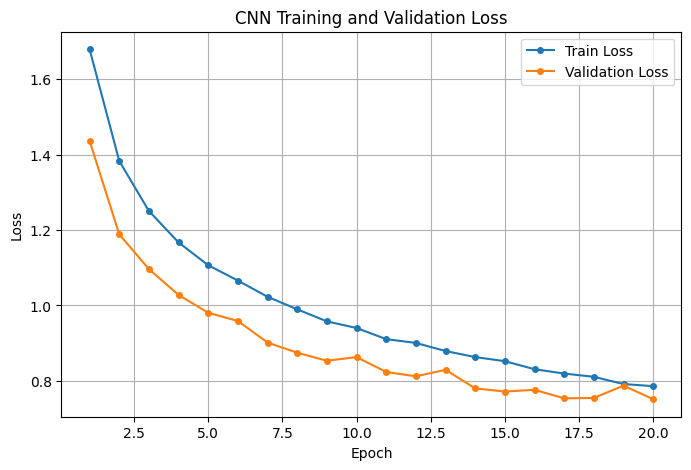

In [127]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, marker="o", markersize=4, label="Train Loss")
plt.plot(epochs, val_losses, marker="o", markersize=4, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

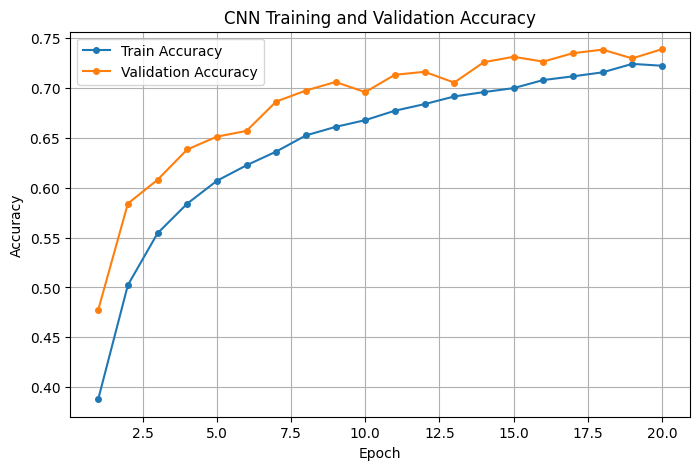

In [128]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_accuracies, marker="o", markersize=4, label="Train Accuracy")
plt.plot(epochs, val_accuracies, marker="o", markersize=4, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [12]:
model = SimpleCNN().to(device)

model.load_state_dict(
    torch.load(
        "cnn_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Model loaded successfully")

Model loaded successfully


In [13]:
all_true_labels = []
all_predicted_labels = []

with torch.no_grad():
  for images, labels in test_loader:

    images = images.to(device)

    outputs = model(images)
    predicted_classes = outputs.argmax(dim=1)

    all_true_labels.extend(labels.cpu().tolist())
    all_predicted_labels.extend(predicted_classes.cpu().tolist())

print("True labels:", len(all_true_labels))
print("Predicted labels:", len(all_predicted_labels))

True labels: 10000
Predicted labels: 10000


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

test_accuracy = accuracy_score(
    all_true_labels,
    all_predicted_labels
)

test_precision = precision_score(
    all_true_labels,
    all_predicted_labels,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    all_true_labels,
    all_predicted_labels,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    all_true_labels,
    all_predicted_labels,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test F1-score:  {test_f1:.4f}")

Test Accuracy:  0.7369
Test Precision: 0.7421
Test Recall:    0.7369
Test F1-score:  0.7367
